# Etapa 2 · Modelo final: división, Pipeline, GridSearchCV y evaluación
**Proyecto Integrador — Heart Failure Prediction**

Qué vamos a hacer:
1. Dividir los datos **primero** (entrenamiento / prueba).
2. Entrenar un `Pipeline` con `GridSearchCV` (usamos RandomForest, el ganador por AUC_cv en la Etapa 1).
3. Evaluar **una sola vez** en el conjunto de prueba: matriz de confusión, curva ROC y AUC.
4. Guardar el modelo en `model.joblib` para la API (Etapa 3).

## 0. Preparación
Igual que en la Etapa 1: sube `heart.csv` cuando Colab te lo pida.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, confusion_matrix, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42

try:  # en Colab
    from google.colab import files
    subido = files.upload()
    RUTA = next(iter(subido))
except ImportError:  # fuera de Colab
    RUTA = "heart.csv"
print("Archivo:", RUTA)

Saving heart.csv to heart.csv
Archivo: heart.csv


## 1. Cargar y dividir **antes** de transformar
Se repite la limpieza de la Etapa 1 (ceros falsos → `NaN`) y luego se divide:

* 80 % entrenamiento, 20 % prueba.
* `stratify=y` mantiene la misma proporción de enfermos en ambos conjuntos.
* A partir de aquí, el conjunto de prueba **no se toca** hasta la sección 4.

In [2]:
df = pd.read_csv(RUTA, encoding="utf-8-sig")
TARGET = "HeartDisease" if "HeartDisease" in df.columns else "target"

for col in ["Cholesterol", "RestingBP"]:
    if col in df.columns:
        df[col] = df[col].replace(0, np.nan)

X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("\nProporción de enfermos (train):", round(y_train.mean(), 3))
print("Proporción de enfermos (test): ", round(y_test.mean(), 3))

Entrenamiento: (734, 11) | Prueba: (184, 11)

Proporción de enfermos (train): 0.553
Proporción de enfermos (test):  0.554


## 2. El Pipeline
Mismo preprocesamiento de la Etapa 1, ahora con **un solo modelo**:

| Paso | Qué hace |
|---|---|
| `prep` (numéricas) | imputar mediana → escalar a [0, 1] |
| `prep` (texto) | imputar moda → one-hot |
| `clf` | `RandomForestClassifier` |

`GridSearchCV` prueba cada combinación de hiperparámetros con validación cruzada de 5
pliegues y se queda con la de mayor AUC. Al final **reentrena** con todo el entrenamiento
(`refit=True`, por defecto).

In [3]:
def build_preprocessor(X):
    num_cols = X.select_dtypes(include="number").columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    pasos = [("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                               ("scaler", MinMaxScaler())]), num_cols)]
    if cat_cols:
        pasos.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
                      cat_cols))
    return ColumnTransformer(pasos)


pipe = Pipeline([("prep", build_preprocessor(X_train)),
                 ("clf", RandomForestClassifier(random_state=RANDOM_STATE))])

param_grid = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [3, 5, None],
    "clf__min_samples_leaf": [1, 5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Mejores parámetros:", grid.best_params_)
print("AUC en validación cruzada:", round(grid.best_score_, 3))

Mejores parámetros: {'clf__max_depth': None, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 100}
AUC en validación cruzada: 0.931


## 3. Evaluación en el conjunto de prueba
Primera (y única) vez que se usa `X_test`. Se calcula:

* **AUC**: qué tan bien separa el modelo enfermos de sanos (1 = perfecto, 0.5 = azar).
* **Accuracy**: porcentaje de aciertos con umbral 0.5.
* **Reporte por clase**: *precision*, *recall* y *f1*.

In [4]:
proba = grid.predict_proba(X_test)[:, 1]
pred = grid.predict(X_test)

print("AUC (prueba):     ", round(roc_auc_score(y_test, proba), 3))
print("Accuracy (prueba):", round(accuracy_score(y_test, pred), 3))
print()
print(classification_report(y_test, pred, target_names=["sano (0)", "enfermo (1)"]))

AUC (prueba):      0.93
Accuracy (prueba): 0.875

              precision    recall  f1-score   support

    sano (0)       0.89      0.82      0.85        82
 enfermo (1)       0.86      0.92      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.87      0.87       184
weighted avg       0.88      0.88      0.87       184



### Matriz de confusión y curva ROC

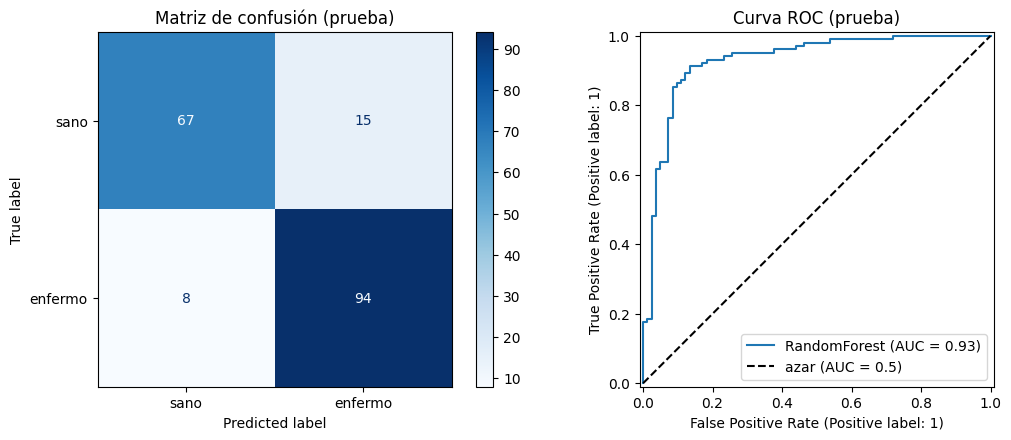

Verdaderos negativos: 67 | Falsos positivos: 15
Falsos negativos:     8 | Verdaderos positivos: 94


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["sano", "enfermo"], cmap="Blues", ax=axes[0])
axes[0].set_title("Matriz de confusión (prueba)")

RocCurveDisplay.from_predictions(y_test, proba, name="RandomForest", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="azar (AUC = 0.5)")
axes[1].set_title("Curva ROC (prueba)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Verdaderos negativos: {tn} | Falsos positivos: {fp}")
print(f"Falsos negativos:     {fn} | Verdaderos positivos: {tp}")

**Cómo leerlas**

* En la matriz, la diagonal son los aciertos. Fuera de la diagonal están los errores.
* Un **falso negativo** es un paciente enfermo al que el modelo llamó sano.
* La curva ROC muestra el compromiso entre detectar enfermos (eje Y) y dar falsas alarmas
  (eje X) al mover el umbral. Cuanto más pegada a la esquina superior izquierda, mejor.

> Pregunta para ti: en un problema médico, ¿qué error es más grave, un falso negativo o un
> falso positivo? ¿Qué métrica del reporte (*precision* o *recall* de la clase "enfermo")
> te dice cuántos de los falsos negativos estás evitando?

## 4. Guardar el modelo
Se guarda **el Pipeline completo** (preprocesamiento + modelo), no solo el clasificador.
Así la API de la Etapa 3 recibe datos crudos y aplica exactamente las mismas
transformaciones.

In [6]:
joblib.dump(grid.best_estimator_, "model.joblib")
print("Variables que espera el modelo:")
print(list(grid.best_estimator_.feature_names_in_))

# Prueba rápida: recargar y predecir con un paciente de prueba
modelo = joblib.load("model.joblib")
print("\nProbabilidad de enfermedad del primer paciente de prueba:",
      round(modelo.predict_proba(X_test.iloc[[0]])[0, 1], 3))

try:  # en Colab, descarga el archivo a tu computador
    files.download("model.joblib")
except NameError:
    pass

Variables que espera el modelo:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope']

Probabilidad de enfermedad del primer paciente de prueba: 0.957


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import sklearn
print(sklearn.__version__)

1.6.1


## 5. Para cerrar la Etapa 2
Escribe en 3–4 líneas:
* qué hiperparámetros eligió `GridSearchCV` y cuál fue el AUC en validación cruzada;
* AUC y accuracy en prueba, y si se parecen al AUC_cv (si son muy distintos, algo anda mal);
* cuántos falsos negativos hubo y por qué importan.

**Siguiente:** Etapa 3 — la API con FastAPI y Docker (se hace en tu Mac con el `model.joblib`
que acabas de descargar).